# Vẽ ảnh hưởng của tốc độ học trên hàm bậc hai (mục 5.1.4)

Hàm f(x) = (x + 2)^2, x0 = 0, chạy 8 vòng lặp với η = 0.25, 0.75, 1 và 1.05

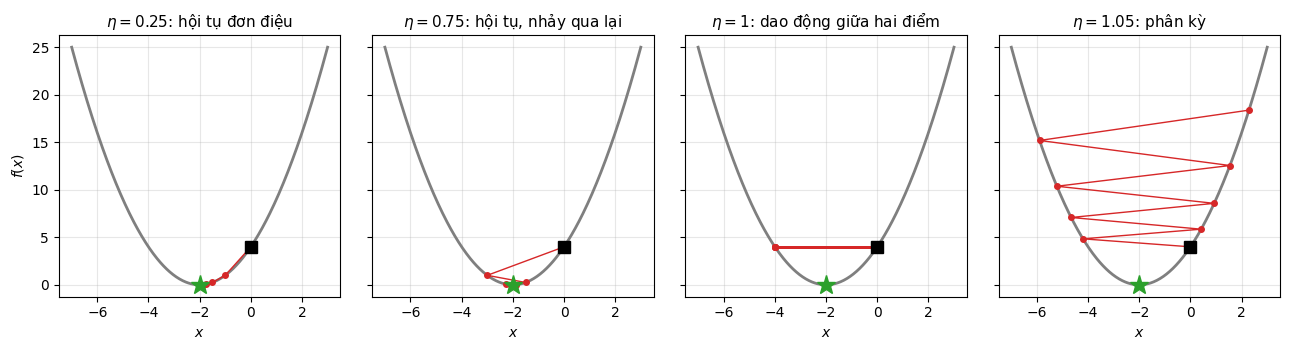

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

IMAGES = Path('.')   # thư mục images/ (notebook chạy trong images/)

def f(x):
    return (x + 2)**2

def grad(x):
    """Đạo hàm f'(x)."""
    return 2 * x + 4

def gd(x0, eta, n_iter=8):
    """GD từ x0 trong n_iter vòng lặp; trả về dãy x qua các vòng lặp."""
    history = [x0]
    for _ in range(n_iter):
        history.append(history[-1] - eta * grad(history[-1]))
    return np.array(history)

# Mỗi trường hợp: tốc độ học η và hiện tượng tương ứng
cases = [(0.25, "hội tụ đơn điệu"), (0.75, "hội tụ, nhảy qua lại"),
         (1.0, "dao động giữa hai điểm"), (1.05, "phân kỳ")]

x_line = np.linspace(-7, 3, 400)
fig, axes = plt.subplots(1, 4, figsize=(13, 3.6), sharey=True)
for ax, (eta, name) in zip(axes, cases):
    x_history = gd(0.0, eta)
    ax.plot(x_line, f(x_line), color="#7F7F7F", lw=2)
    ax.plot(x_history, f(x_history), "o-", color="#D62728", ms=4, lw=1)
    ax.plot(x_history[0], f(x_history[0]), "s", color="black", ms=8)
    ax.plot(-2, 0, "*", color="#2CA02C", ms=14)
    ax.set_title(f"$\\eta = {eta:g}$: {name}", fontsize=11)
    ax.set_xlabel("$x$"); ax.grid(alpha=0.3)
axes[0].set_ylabel("$f(x)$")
fig.tight_layout()
fig.savefig(IMAGES / "learning_rate_quadratic.png", dpi=150)